# Stage 3 — Exploratory Data Analysis

## Introduction

`02_sql_analysis.ipynb` answered the core business question — *who defaults and at what rate?* — through exact, reproducible SQL queries at portfolio scale: grade (6.7% → 51.4%), FICO (25.1% → 10.1%), term (17.2% → 34.6%), DTI (16.4% → 31.1%), and a profitability collapse from +$1,926/loan (2013) to −$3,283/loan (2018). SQL is the right tool for those metrics — precise, auditable, and runs in seconds on 1.37M rows.

What SQL cannot easily show is how risk compounds continuously across the full range of grade, FICO, and DTI combinations - not just one named intersection. `02_sql_analysis.ipynb` confirmed that the Grade G / Fair FICO / Very High DTI combination defaults at 60.29% (2.8x the portfolio average), but that is a single, hand-picked cell. This notebook does two things SQL alone cannot:

1. **Visualizes** the SQL findings to make the scale and risk spreads immediately readable — volume vs. default rate side by side so a high-rate but low-volume segment can be distinguished from a genuine portfolio-level driver.
2. **Surfaces interaction effects** — how grade, FICO, DTI, and income compound in the same borrower, creating risk concentrations that motivate the multi-variable approach used in Stage 5 onward.

---

## Contents

**Input:** `../data/cleaned_data.csv` — produced by `01_data_cleaning.ipynb`
**SQL findings to confirm and extend:** Default rates by 7 dimensions + vintage profitability arc from `02_sql_analysis.ipynb`

1. **Setup & Data Loading** — Libraries, data load, and quick sanity check.
1. **Default Rate by Category** — Visual confirmation of the SQL segment rates; volume vs. rate side by side for each dimension.
1. **Bivariate & Correlation Analysis** — The section SQL cannot do: interaction heatmaps, scatter plots, and the multicollinearity structure of predictors.
1. **Temporal Analysis** — Default rate trends and grade-mix evolution over 2007–2018.
1. **Key Findings** — Phase 1 synthesis across Stages 1–3; the analytical foundation that motivates the Basel II/III modelling in Phase 2.

> **Phase 2 preview:** The EDA findings — grade as the dominant predictor, no single variable cleanly separating defaults, multi-variable risk compounding — directly motivate the approach taken in Phase 2. Stages 5–9 (`03 modeling/`) translate these patterns into formal credit risk models: a PD model to rank default likelihood, LGD and EAD models to quantify severity, and a portfolio-level Expected Loss calculation (EL = PD × LGD × EAD).

---

## 1. Setup & Data Loading

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Consistent plot style
sns.set_theme(style="whitegrid", palette="Blues_r")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("../data/cleaned_data.csv")

print(f"Rows: {len(df):,}  |  Columns: {df.shape[1]}")
df.head()

Rows: 1,371,165  |  Columns: 20


,grade,delinq_2yrs,inq_last_6mths,dti,annual_inc,revol_util,loan_amnt,int_rate,term,purpose,installment,total_acc,open_acc,mths_since_last_delinq,total_pymnt,default,ever_delinq,credit_history_months,issue_year,fico_score
0,C,0,1,5.91,55000.0,29.7,3600.0,13.99,36,debt_consolidation,123.03,13,7,30.0,4421.72,0,1,148,2015,677.0
1,C,1,4,16.06,65000.0,19.2,24700.0,11.99,36,small_business,820.28,38,22,6.0,25679.66,0,1,192,2015,717.0
2,B,0,0,10.78,63000.0,56.2,20000.0,10.78,60,home_improvement,432.66,18,6,31.0,22705.92,0,0,184,2015,697.0
3,F,1,3,25.37,104433.0,64.5,10400.0,22.45,60,major_purchase,289.91,35,12,12.0,11740.50,0,1,210,2015,697.0
4,C,0,0,10.20,34000.0,68.4,11950.0,13.44,36,debt_consolidation,405.18,6,5,31.0,13708.95,0,0,338,2015,692.0


---

## 2. Default Rate by Category

`02_sql_analysis.ipynb` already computed these segment rates as table rows. Here we pair **loan volume (left) and default rate (right)** side by side for each dimension — because a segment can look dangerous in isolation but represent too little volume to matter, or carry massive volume at a below-average rate. The visual layer makes that trade-off immediately readable at a glance.

Each sub-section plots both bars together, with a dashed line marking the **21.47% portfolio average**. Income is not charted here — Notebook 2 found it a weak standalone predictor — but it reappears in Section 3.4, combined with grade.

### 2.1 Default rate by purpose

Volume and default rate across all 14 loan purposes, paired to test whether high-volume segments carry more or less risk than the portfolio average.

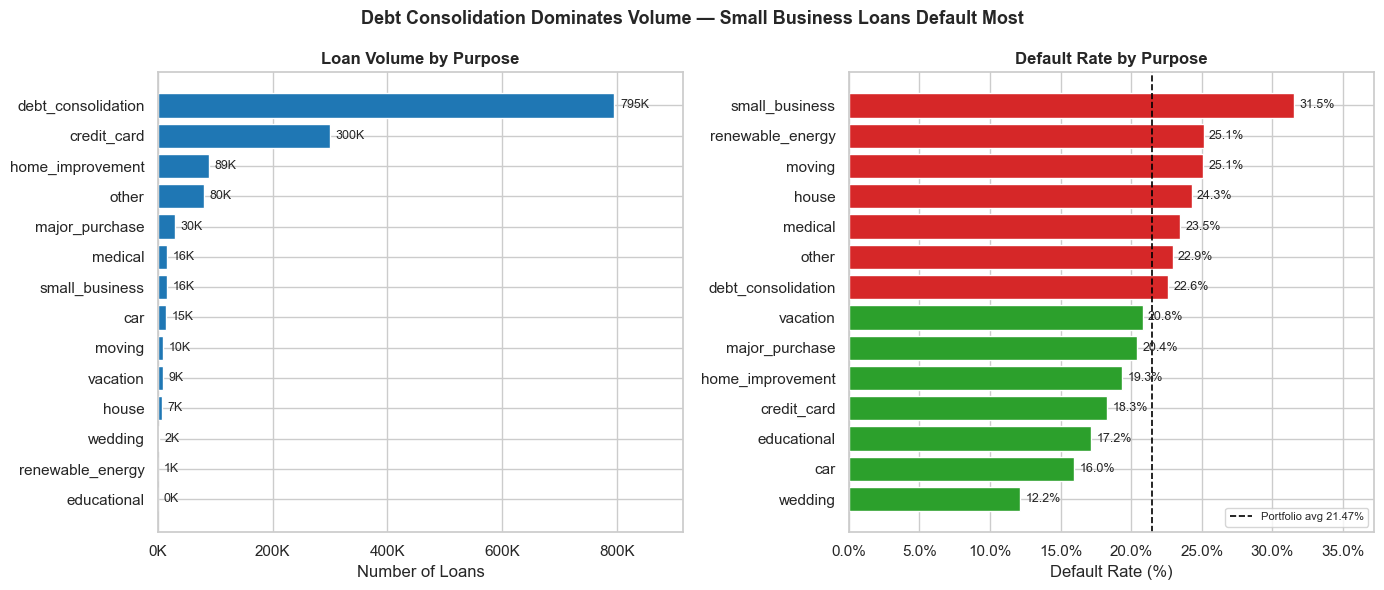

In [24]:
PORTFOLIO_AVG = 21.47

purpose_stats = (
    df.groupby("purpose")["default"]
    .agg(total="count", defaults="sum")
    .assign(default_rate=lambda x: x["defaults"] / x["total"] * 100)
)

purpose_by_vol  = purpose_stats.sort_values("total")
purpose_by_rate = purpose_stats.sort_values("default_rate")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Left: Volume ---
bars0 = axes[0].barh(purpose_by_vol.index, purpose_by_vol["total"], color="#1f77b4", edgecolor="white")
axes[0].bar_label(bars0, labels=[f"{v/1e3:.0f}K" for v in purpose_by_vol["total"]], padding=4, fontsize=9)
axes[0].set_title("Loan Volume by Purpose", fontweight="bold")
axes[0].set_xlabel("Number of Loans")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
axes[0].set_xlim(right=purpose_by_vol["total"].max() * 1.15)

# --- Right: Default Rate ---
rate_colors = ["#2ca02c" if r < PORTFOLIO_AVG else "#d62728" for r in purpose_by_rate["default_rate"]]
bars1 = axes[1].barh(purpose_by_rate.index, purpose_by_rate["default_rate"], color=rate_colors, edgecolor="white")
axes[1].bar_label(bars1, fmt="%.1f%%", padding=4, fontsize=9)
axes[1].axvline(PORTFOLIO_AVG, color="black", linestyle="--", linewidth=1.2, label=f"Portfolio avg {PORTFOLIO_AVG}%")
axes[1].set_title("Default Rate by Purpose", fontweight="bold")
axes[1].set_xlabel("Default Rate (%)")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_xlim(right=purpose_by_rate["default_rate"].max() * 1.18)
axes[1].legend(fontsize=8)

plt.suptitle("Debt Consolidation Dominates Volume — Small Business Loans Default Most", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.2 Default rate by credit grade

Volume and default rate side by side across all seven grades, from A (lowest risk) to G (highest).

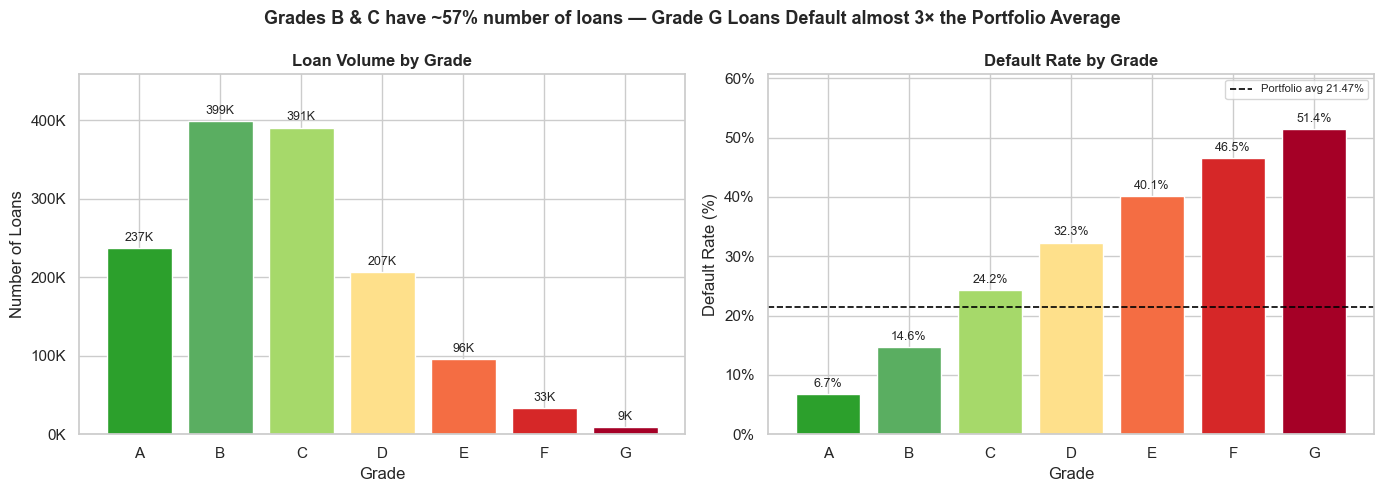

In [25]:
PORTFOLIO_AVG = 21.47

grade_stats = (
    df.groupby("grade")["default"]
    .agg(total="count", defaults="sum")
    .assign(default_rate=lambda x: x["defaults"] / x["total"] * 100)
    .sort_index()
)

# Green → Red gradient across grades A to G
grade_colors = ["#2ca02c", "#5aae61", "#a6d96a", "#fee08b", "#f46d43", "#d62728", "#a50026"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: Volume ---
bars0 = axes[0].bar(grade_stats.index, grade_stats["total"], color=grade_colors, edgecolor="white")
axes[0].bar_label(bars0, labels=[f"{v/1e3:.0f}K" for v in grade_stats["total"]], padding=3, fontsize=9)
axes[0].set_title("Loan Volume by Grade", fontweight="bold")
axes[0].set_xlabel("Grade")
axes[0].set_ylabel("Number of Loans")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
axes[0].set_ylim(top=grade_stats["total"].max() * 1.15)

# --- Right: Default Rate ---
bars1 = axes[1].bar(grade_stats.index, grade_stats["default_rate"], color=grade_colors, edgecolor="white")
axes[1].bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=9)
axes[1].axhline(PORTFOLIO_AVG, color="black", linestyle="--", linewidth=1.2, label=f"Portfolio avg {PORTFOLIO_AVG}%")
axes[1].set_title("Default Rate by Grade", fontweight="bold")
axes[1].set_xlabel("Grade")
axes[1].set_ylabel("Default Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_ylim(top=grade_stats["default_rate"].max() * 1.18)
axes[1].legend(fontsize=8)

plt.suptitle("Grades B & C have ~57% number of loans — Grade G Loans Default almost 3× the Portfolio Average",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Default rate by FICO band

Banding into three tiers reveals how volume distributes across credit quality levels and how each tier compares to the portfolio average. No loans with FICO below 600 appear in this dataset — Lending Club's underwriting rejects them at origination — a scope limit worth keeping in mind for every FICO-based finding in this project.

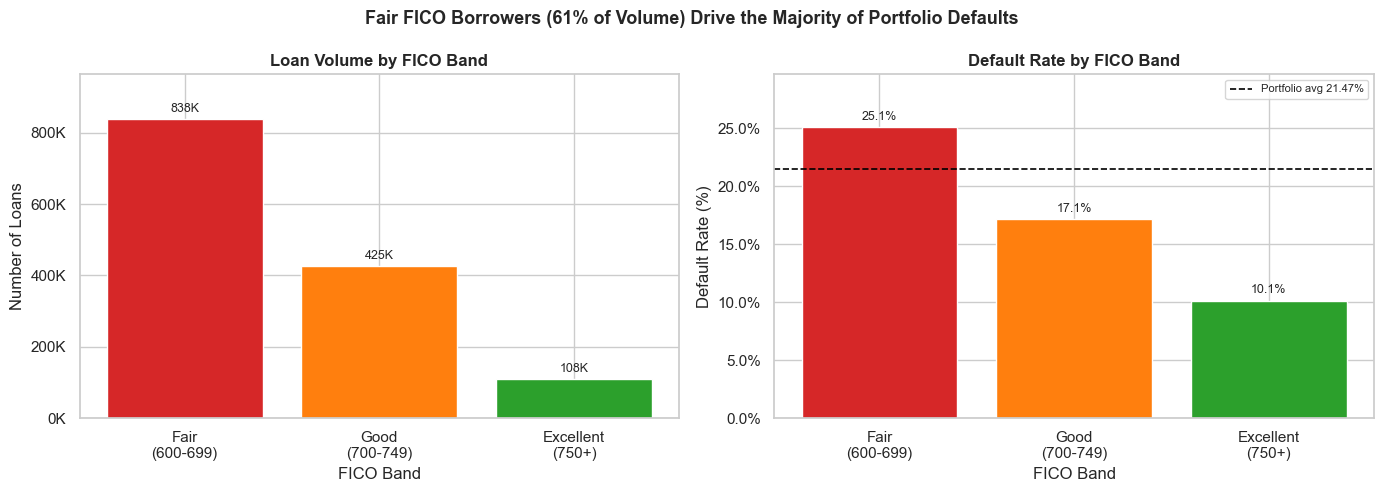

In [26]:
PORTFOLIO_AVG = 21.47

fico_bands = pd.cut(
    df["fico_score"],
    bins=[600, 700, 750, 900],
    labels=["Fair\n(600-699)", "Good\n(700-749)", "Excellent\n(750+)"],
    right=False
)

fico_stats = (
    df.assign(fico_band=fico_bands)
    .groupby("fico_band", observed=False)["default"]
    .agg(total="count", defaults="sum")
    .assign(default_rate=lambda x: x["defaults"] / x["total"] * 100)
)

band_colors = ["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: Volume ---
bars0 = axes[0].bar(fico_stats.index, fico_stats["total"], color=band_colors, edgecolor="white")
axes[0].bar_label(bars0, labels=[f"{v/1e3:.0f}K" for v in fico_stats["total"]], padding=3, fontsize=9)
axes[0].set_title("Loan Volume by FICO Band", fontweight="bold")
axes[0].set_xlabel("FICO Band")
axes[0].set_ylabel("Number of Loans")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
axes[0].set_ylim(top=fico_stats["total"].max() * 1.15)

# --- Right: Default Rate ---
bars1 = axes[1].bar(fico_stats.index, fico_stats["default_rate"], color=band_colors, edgecolor="white")
axes[1].bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=9)
axes[1].axhline(PORTFOLIO_AVG, color="black", linestyle="--", linewidth=1.2, label=f"Portfolio avg {PORTFOLIO_AVG}%")
axes[1].set_title("Default Rate by FICO Band", fontweight="bold")
axes[1].set_xlabel("FICO Band")
axes[1].set_ylabel("Default Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_ylim(top=fico_stats["default_rate"].max() * 1.18)
axes[1].legend(fontsize=8)

plt.suptitle("Fair FICO Borrowers (61% of Volume) Drive the Majority of Portfolio Defaults",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.4 Default rate by loan term

Volume and default rate for 36- vs. 60-month loans, side by side.

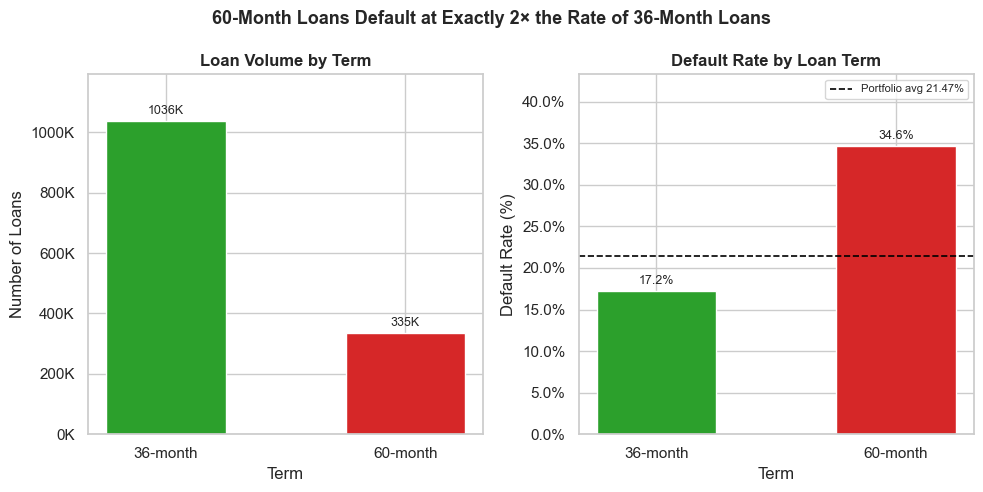

In [27]:
PORTFOLIO_AVG = 21.47

term_stats = (
    df.groupby("term")["default"]
    .agg(total="count", defaults="sum")
    .assign(default_rate=lambda x: x["defaults"] / x["total"] * 100)
    .sort_index()
)

term_labels = [f"{int(t)}-month" for t in term_stats.index]
term_colors  = ["#2ca02c", "#d62728"]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# --- Left: Volume ---
bars0 = axes[0].bar(term_labels, term_stats["total"], color=term_colors, edgecolor="white", width=0.5)
axes[0].bar_label(bars0, labels=[f"{v/1e3:.0f}K" for v in term_stats["total"]], padding=3, fontsize=9)
axes[0].set_title("Loan Volume by Term", fontweight="bold")
axes[0].set_xlabel("Term")
axes[0].set_ylabel("Number of Loans")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
axes[0].set_ylim(top=term_stats["total"].max() * 1.15)

# --- Right: Default Rate ---
bars1 = axes[1].bar(term_labels, term_stats["default_rate"], color=term_colors, edgecolor="white", width=0.5)
axes[1].bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=9)
axes[1].axhline(PORTFOLIO_AVG, color="black", linestyle="--", linewidth=1.2, label=f"Portfolio avg {PORTFOLIO_AVG}%")
axes[1].set_title("Default Rate by Loan Term", fontweight="bold")
axes[1].set_xlabel("Term")
axes[1].set_ylabel("Default Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_ylim(top=term_stats["default_rate"].max() * 1.25)
axes[1].legend(fontsize=8)

plt.suptitle("60-Month Loans Default at Exactly 2× the Rate of 36-Month Loans",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.5 Default rate by DTI

Volume and default rate across five DTI bands, from 0–10 to 40+.

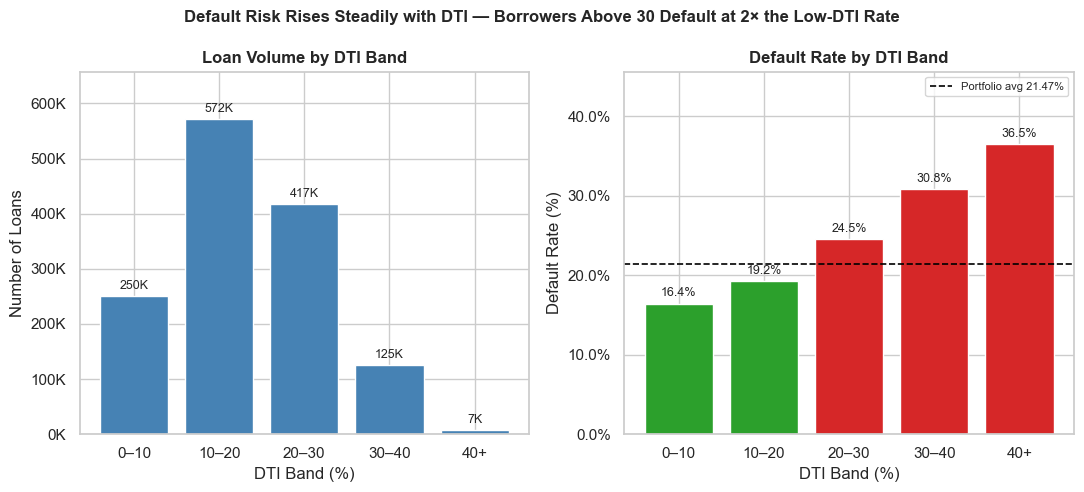

In [28]:
PORTFOLIO_AVG = 21.47

dti_bins   = [0, 10, 20, 30, 40, df["dti"].max() + 1]
dti_labels = ["0–10", "10–20", "20–30", "30–40", "40+"]

dti_stats = (
    df.assign(dti_band=pd.cut(df["dti"], bins=dti_bins, labels=dti_labels, right=False))
    .groupby("dti_band", observed=True)["default"]
    .agg(total="count", defaults="sum")
    .assign(default_rate=lambda x: x["defaults"] / x["total"] * 100)
)

palette = ["#2ca02c" if r < PORTFOLIO_AVG else "#d62728" for r in dti_stats["default_rate"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# --- Left: Volume ---
bars0 = axes[0].bar(dti_stats.index, dti_stats["total"], color="steelblue", edgecolor="white")
axes[0].bar_label(bars0, labels=[f"{v/1e3:.0f}K" for v in dti_stats["total"]], padding=3, fontsize=9)
axes[0].set_title("Loan Volume by DTI Band", fontweight="bold")
axes[0].set_xlabel("DTI Band (%)")
axes[0].set_ylabel("Number of Loans")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}K"))
axes[0].set_ylim(top=dti_stats["total"].max() * 1.15)

# --- Right: Default Rate ---
bars1 = axes[1].bar(dti_stats.index, dti_stats["default_rate"], color=palette, edgecolor="white")
axes[1].bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=9)
axes[1].axhline(PORTFOLIO_AVG, color="black", linestyle="--", linewidth=1.2,
                label=f"Portfolio avg {PORTFOLIO_AVG}%")
axes[1].set_title("Default Rate by DTI Band", fontweight="bold")
axes[1].set_xlabel("DTI Band (%)")
axes[1].set_ylabel("Default Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_ylim(top=dti_stats["default_rate"].max() * 1.25)
axes[1].legend(fontsize=8)

plt.suptitle("Default Risk Rises Steadily with DTI — Borrowers Above 30 Default at 2× the Low-DTI Rate",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### Section 2 takeaways

| Segment | Key observation | Business implication |
|---|---|---|
| Purpose: `debt_consolidation` | ~58% of volume; default rate ~22.6% (near portfolio avg) | Shapes the portfolio-wide average by sheer scale |
| Purpose: `small_business` | **31.5% default** — highest of all 14 purposes | Concentrated exposure worth a dedicated pricing review (~16K loans) |
| Credit grade | Default rises monotonically from **6.7% (A) → 51.4% (G)** — 44.7pp spread | Widest risk spread of any variable in the dataset |
| Grade mix | B + C hold ~57% of volume at 14.6% and 24.2% in default | Platform concentrates in mid-risk origination |
| FICO band | Fair (600–699): **25.1%**; Excellent (750+): **10.1%** — 15pp spread | Fair band (61% of volume) is the highest-leverage segment |
| Loan term | 60-month: **34.6%** default — exactly **2× the 36-month rate (17.2%)** | Structural risk amplifier independent of grade |
| DTI band | Borrowers with DTI 30+ default at roughly **2× the rate of DTI 0–10** | Forward-looking stress indicator; sharpens segmentation combined with grade and FICO |

---

## 3. Bivariate & Correlation Analysis

Section 2 confirmed what the SQL queries already showed — segment-level default rates that hold up visually. This section goes beyond what SQL can easily produce: it examines **how variables interact with each other**.

Four analyses that single-dimension SQL queries cannot cleanly surface:

- **Correlation heatmap** — Pearson correlations across all numeric features, flagging multicollinear pairs. The clearest structural redundancy: `loan_amnt` and `installment` correlate at r = 0.95 — installment is mathematically derived from loan amount, rate, and term, making them redundant as joint predictors in any model.
- **Interest rate by grade (default vs. non-default)** — Within each grade, whether defaulted loans were priced differently from non-defaulted ones — testing whether the platform's rate-setting anticipated intra-grade risk differences.
- **FICO vs. interest rate scatter** — The joint default pattern across FICO quality and pricing simultaneously. The −0.40 correlation means FICO drives rate assignment but does not determine it — defaults scatter across the full FICO–rate space, and no single threshold cleanly separates them.
- **Income × Grade and FICO × Term heatmaps** — How income interacts with grade, and how FICO quality compounds with loan term. These two panels quantify the interaction effects that motivate multi-variable scoring: grade dominates income, and term amplifies default risk at every FICO tier, though the multiplier varies (1.9×–2.7×) rather than staying constant.

### 3.1 Correlation heatmap of numeric features

A Pearson correlation matrix across all numeric columns — flags linear relationships between predictors and with the `default` target, and identifies multicollinear variable pairs that would be problematic in a regression or scoring model.

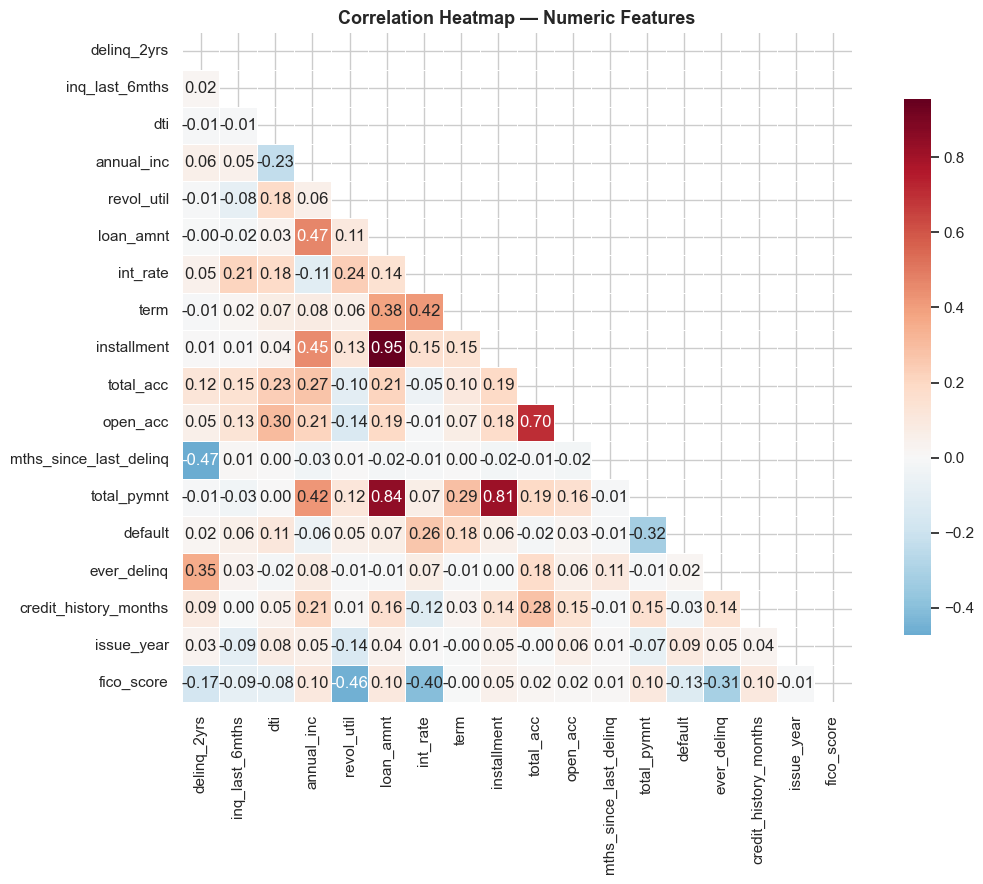

In [29]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, linewidths=0.5, square=True, cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap — Numeric Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 3.2 Interest rate by grade (default vs. non-default)

Within each grade, this boxplot shows whether defaulted and non-defaulted loans were priced differently — testing whether the platform's rate-setting anticipated intra-grade risk differences.

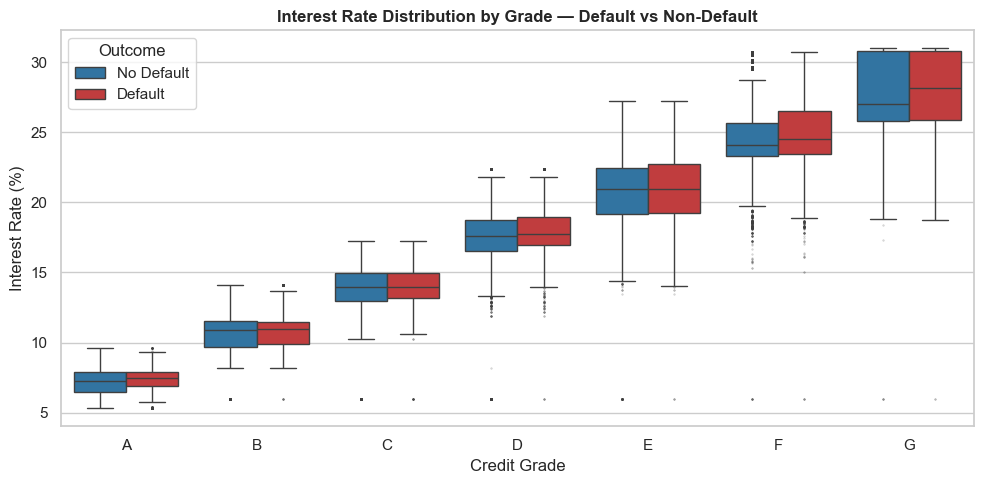

In [30]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df, x="grade", y="int_rate", hue="default",
    order=sorted(df["grade"].dropna().unique()),
    palette={0: "#1f77b4", 1: "#d62728"},
    flierprops=dict(marker=".", markersize=1, alpha=0.3)
)
plt.title("Interest Rate Distribution by Grade — Default vs Non-Default", fontsize=12, fontweight="bold")
plt.xlabel("Credit Grade")
plt.ylabel("Interest Rate (%)")
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, ["No Default", "Default"], title="Outcome")
plt.tight_layout()
plt.show()

### 3.3 FICO Score vs Interest Rate — Default Patterns

A random sample of 10,000 loans is used to keep the scatter plot readable.

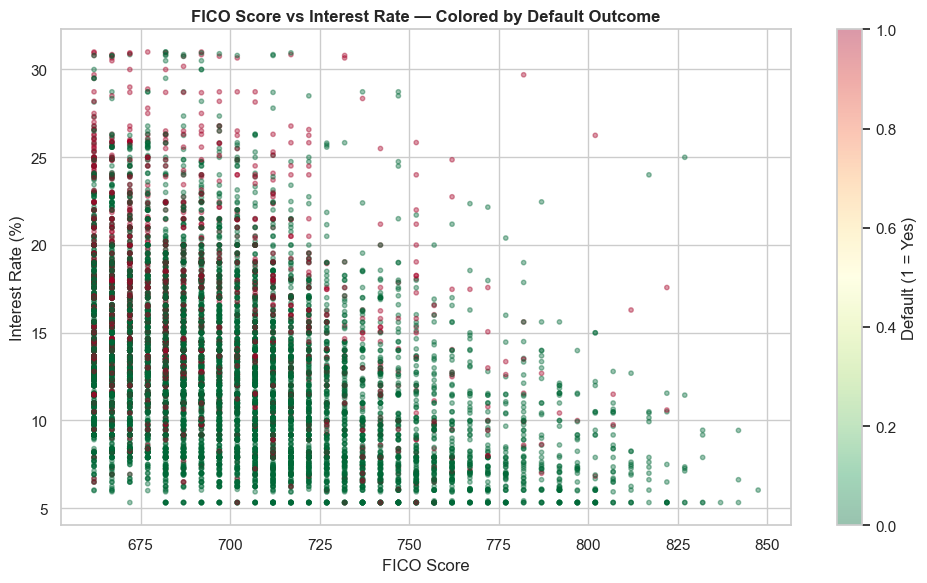

In [31]:
sample = df.sample(10_000, random_state=42)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    sample["fico_score"], sample["int_rate"],
    c=sample["default"], cmap="RdYlGn_r",
    alpha=0.4, s=10
)
cbar = plt.colorbar(scatter)
cbar.set_label("Default (1 = Yes)")
plt.title("FICO Score vs Interest Rate — Colored by Default Outcome", fontsize=12, fontweight="bold")
plt.xlabel("FICO Score")
plt.ylabel("Interest Rate (%)")
plt.tight_layout()
plt.show()

### 3.4 Combined Risk Surfaces — Income × Grade and FICO × Term

Two interaction heatmaps that surface risk compounding no single-variable query can detect. The first crosses income with credit grade — showing that grade dominates: moving across grade bands shifts default rate by 40+ pp, while income modifies it by only 3–7 pp within any given grade. The second crosses FICO band with loan term — combining the two strongest numeric predictors to quantify compounding: the same FICO-quality borrower faces a materially higher default rate on a 60-month term than a 36-month term, and that gap widens as credit quality falls.

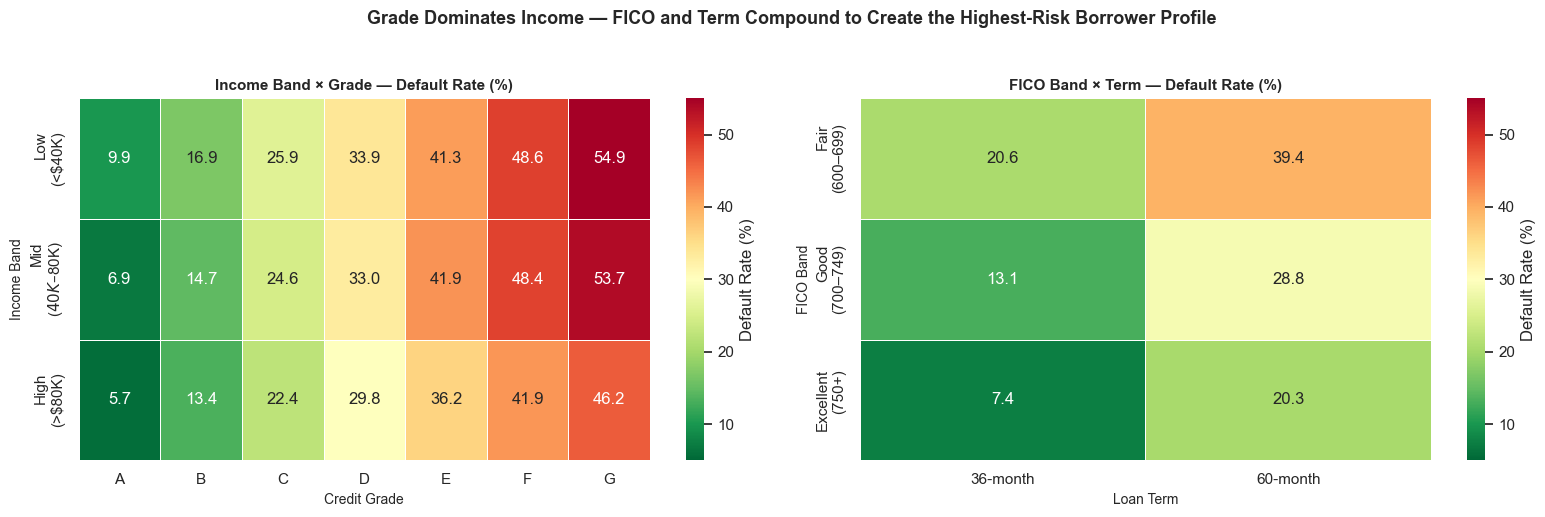

In [32]:
PORTFOLIO_AVG = 21.47

income_bins   = [0, 40_000, 80_000, df["annual_inc"].max() + 1]
income_labels = ["Low\n(<$40K)", "Mid\n($40K–$80K)", "High\n(>$80K)"]

fico_bins   = [600, 700, 750, 900]
fico_labels = ["Fair\n(600–699)", "Good\n(700–749)", "Excellent\n(750+)"]

df_tmp = df.assign(
    income_band=pd.cut(df["annual_inc"], bins=income_bins, labels=income_labels, right=False),
    fico_band=pd.cut(df["fico_score"],   bins=fico_bins,   labels=fico_labels, right=False),
)

pivot_grade = (
    df_tmp.groupby(["income_band", "grade"], observed=True)["default"]
    .mean().mul(100)
    .unstack("grade")
    .reindex(income_labels)
)

pivot_term = (
    df_tmp.groupby(["fico_band", "term"], observed=True)["default"]
    .mean().mul(100)
    .unstack("term")
    .reindex(fico_labels)
)
pivot_term.columns = [f"{int(c)}-month" for c in pivot_term.columns]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(
    "Grade Dominates Income — FICO and Term Compound to Create the Highest-Risk Borrower Profile",
    fontsize=13, fontweight="bold", y=1.03,
)

# Panel 1 — Income × Grade
sns.heatmap(
    pivot_grade, ax=axes[0],
    cmap="RdYlGn_r", annot=True, fmt=".1f",
    linewidths=0.5, vmin=5, vmax=55,
    cbar_kws={"label": "Default Rate (%)"},
)
axes[0].set_title("Income Band × Grade — Default Rate (%)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Credit Grade", fontsize=10)
axes[0].set_ylabel("Income Band", fontsize=10)

# Panel 2 — FICO Band × Term
sns.heatmap(
    pivot_term, ax=axes[1],
    cmap="RdYlGn_r", annot=True, fmt=".1f",
    linewidths=0.5, vmin=5, vmax=55,
    cbar_kws={"label": "Default Rate (%)"},
)
axes[1].set_title("FICO Band × Term — Default Rate (%)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Loan Term", fontsize=10)
axes[1].set_ylabel("FICO Band", fontsize=10)

plt.tight_layout()
plt.show()

### Section 3 takeaways

| Analysis | Key observation | Business implication |
|---|---|---|
| Correlation: `loan_amnt` vs. `installment` | r = 0.95 — near-perfect collinearity | Structurally redundant as joint predictors |
| Correlation: `fico_score` vs. `int_rate` | r = −0.40 — moderate negative correlation | FICO drives rate but doesn't fully determine it |
| Correlation: `fico_score` vs. `default` | r = −0.13 — smaller than int_rate (0.26) or term (0.18), but the strongest signal independent of grade | Top independent numeric signal for repayment risk |
| Int. rate by grade (default vs. paid) | Rate distributions are nearly identical for defaulted and non-defaulted loans within every grade | Platform prices by grade, not intra-grade risk |
| FICO vs. int_rate scatter | Downward slope confirms r = −0.40; within any FICO band, defaults and non-defaults span nearly the same rate range | No threshold on either axis separates the classes |
| Income × Grade & FICO × Term heatmaps | Grade dominates income (7.2pp swing within Grade G vs. 45pp+ across grades); FICO × Term multiplier holds at every tier | Term can erase the advantage of better credit quality (see Finding 3) |

---

## 4. Temporal Analysis

The portfolio spans 12 vintage years (2007–2018), during which loan volume and grade mix both shifted materially. Analyzing these dimensions over time reveals how growth strategy and borrower composition changed — and provides critical context for interpreting the snapshot-level default rates seen in Section 2.

### 4.1 Loan volume growth and vintage default rate

Macro portfolio trajectory from 2007 to 2018. Volume bars show annual origination scale; the trend line tracks each vintage cohort's realized default rate against the portfolio average. **Maturity bias note:** 2017–2018 vintages already carry the highest observed rates in the portfolio (~27%), but these figures are inflated, not a lower bound — the loans still active in these cohorts (the majority, for 2018) were dropped during cleaning, leaving behind only the loans that already resolved, which skew toward early defaults. The same bias documented in `02_sql_analysis.ipynb` applies here: recent cohorts are overcounted on the default side, so the true eventual rate for 2017–2018 vintages will be lower than the ~27% currently observed.

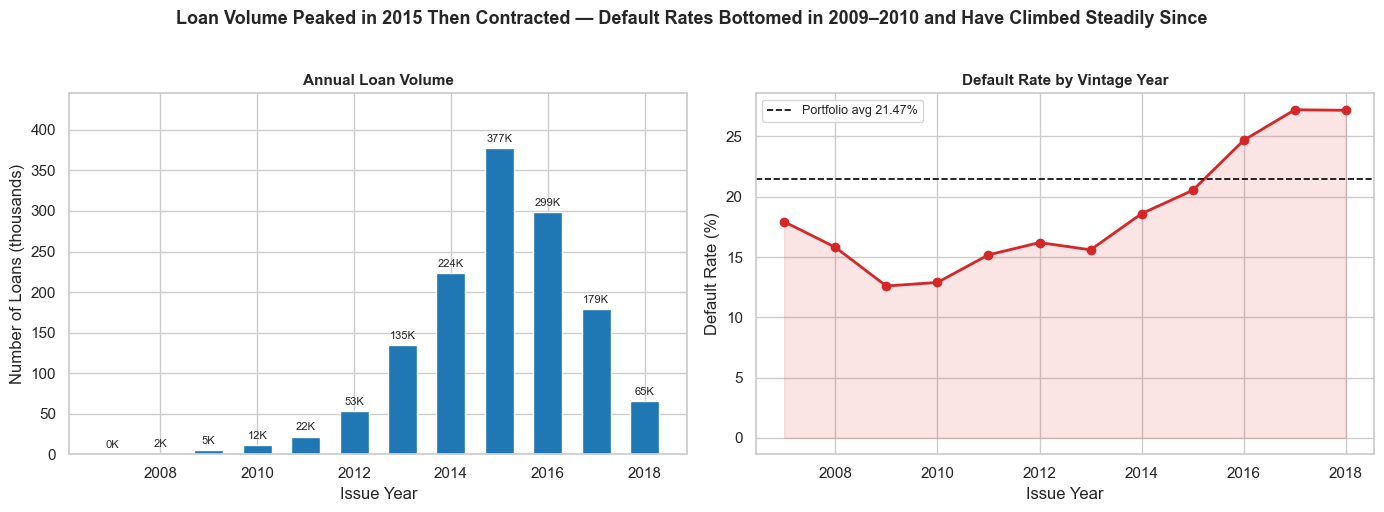

In [33]:
PORTFOLIO_AVG = 21.47

yearly = df.groupby("issue_year").agg(
    loan_count=("default", "count"),
    default_rate=("default", "mean"),
    avg_loan_amnt=("loan_amnt", "mean"),
).reset_index()
yearly["default_rate"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    "Loan Volume Peaked in 2015 Then Contracted — Default Rates Bottomed in 2009–2010 and Have Climbed Steadily Since",
    fontsize=13, fontweight="bold", y=1.02,
)

# Left — Loan Volume
bars = axes[0].bar(yearly["issue_year"], yearly["loan_count"] / 1_000, color="#1f77b4", width=0.6)
axes[0].bar_label(bars, labels=[f"{v:.0f}K" for v in yearly["loan_count"] / 1_000], padding=3, fontsize=8)
axes[0].set_title("Annual Loan Volume", fontweight="bold", fontsize=11)
axes[0].set_xlabel("Issue Year")
axes[0].set_ylabel("Number of Loans (thousands)")
axes[0].set_ylim(top=yearly["loan_count"].max() / 1_000 * 1.18)
axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))

# Right — Vintage Default Rate
axes[1].plot(yearly["issue_year"], yearly["default_rate"], marker="o", color="#d62728", linewidth=2)
axes[1].fill_between(yearly["issue_year"], yearly["default_rate"], alpha=0.12, color="#d62728")
axes[1].axhline(PORTFOLIO_AVG, color="black", linestyle="--", linewidth=1.2,
                label=f"Portfolio avg {PORTFOLIO_AVG}%")
axes[1].set_title("Default Rate by Vintage Year", fontweight="bold", fontsize=11)
axes[1].set_xlabel("Issue Year")
axes[1].set_ylabel("Default Rate (%)")
axes[1].legend(fontsize=9)
axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

### 4.2 Grade mix evolution and default rate by vintage

How the portfolio's A–G grade composition shifted as origination volume scaled. The heatmap tests whether each grade's realized default rate was stable across vintage years or worsened — the latter would indicate underwriting loosening beyond a simple mix effect.

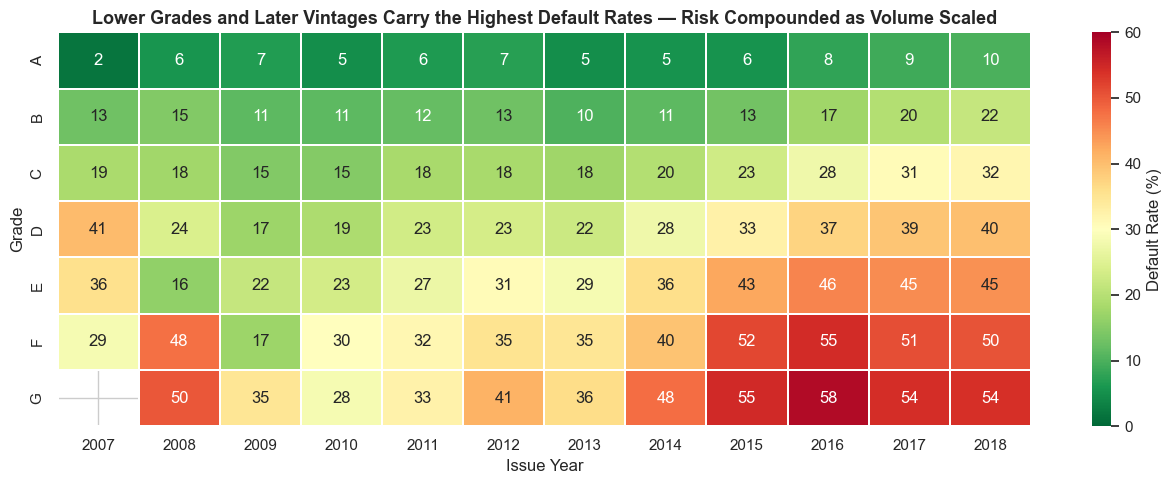

In [34]:
grade_default = (
    df.groupby(["issue_year", "grade"])["default"]
    .mean()
    .mul(100)
    .unstack("grade")
)

plt.figure(figsize=(13, 5))
sns.heatmap(
    grade_default.T,
    cmap="RdYlGn_r",
    annot=True, fmt=".0f",
    linewidths=0.3,
    vmin=0, vmax=60,
    cbar_kws={"label": "Default Rate (%)"},
)
plt.title(
    "Lower Grades and Later Vintages Carry the Highest Default Rates — Risk Compounded as Volume Scaled",
    fontsize=13, fontweight="bold",
)
plt.xlabel("Issue Year")
plt.ylabel("Grade")
plt.tight_layout()
plt.show()

### Section 4 takeaways

| Metric | Key observation | Business implication |
|---|---|---|
| Loan volume | Peaked in 2015–2016, then contracted | Any post-2015 trend must be read in this context |
| Vintage default rate | 2009–2010 lowest (~12–13%); climbed steadily to ~27% by 2017–2018 | Maturity bias means 2017–2018 rates are inflated, not the final figure |
| Grade mix evolution | Grade A share fell from 24.3% (2010) to 19.1% (2015) as volume scaled, absorbed mostly by Grade C (21.4%→27.9%) — not by the riskier D–G tier, which stayed roughly flat (Grade G never exceeded 1.3% of any vintage) | Within-grade deterioration, not mix shift into risky grades, is the bigger driver of rising default rates |
| Default rate by grade x vintage | Within-grade rates rose too — Grade C: 19%->32%, Grade F: 29%->55% | Not purely a mix-shift story (see Finding 5) |

---

## 5. Key Findings

This section synthesizes the most important insights from the full project — cleaning (Notebook 1), SQL analysis (Notebook 2), and exploratory data analysis (this notebook). Every finding is anchored to a specific number from the data.

### Executive Summary

Lending Club originated 1.37 million loans between 2007 and 2018 at a portfolio-wide default rate of **21.47%** — approximately 1 in 5 loans charged off or went delinquent. Credit grade is the dominant risk predictor, with defaults ranging from **6.7% (Grade A) to 51.4% (Grade G)**, a 44.7 percentage-point spread that no other single variable approaches. The dataset reveals that no individual variable cleanly separates defaulters from payers: FICO score is the strongest independent numeric signal — interest rate correlates more strongly with default in raw terms, but only because the platform sets rate based on grade, not because it adds new information — while the decisive factor is the *combination* of grade, FICO, and DTI — not any one of them alone. Structurally, 60-month loans default at exactly twice the rate of 36-month loans (34.6% vs. 17.2%), and the portfolio's risk profile worsened as volume scaled between 2010 and 2015 through two compounding effects: a mix shift away from Grade A (mostly absorbed by Grade C, not the riskier D–G tier), and genuine within-grade deterioration — later vintages defaulted at higher rates than earlier ones even within the same grade, which turns out to be the larger driver.

The profitability picture — quantified in `02_sql_analysis.ipynb` — tells the same story through the income statement: average profit per loan peaked at **$1,926 in 2013**, fell 74% to $505 by 2015 as origination volume peaked at 377K loans, and turned negative by 2016. By 2018, the average loan generated a **−$3,283 loss**. The $257M headline net profit across the full portfolio masks a structural deterioration that was already irreversible by 2015.

---

### Finding 1 — Portfolio Composition Creates Concentrated, Predictable Risk

| Dimension | Key metric |
|---|---|
| Total loans analyzed | **1,371,165** across 2007–2018 |
| Portfolio default rate | **21.47%** |
| Largest purpose segment | `debt_consolidation` — **~58% of volume at 22.6% default** |
| Dominant grades by volume | B + C — **~57% of all loans** |
| Class split | 78.5% non-default / 21.5% default |

`debt_consolidation` alone shapes the headline default rate: it holds ~58% of all volume at a rate essentially equal to the portfolio average, meaning the overall 21.47% figure is, to a significant degree, the debt consolidation segment's default rate. Any material change in origination quality or pricing within this one segment directly moves the portfolio metric. `small_business` loans, by contrast, carry the highest default rate (**31.5%**) of any individual purpose — nearly 10 pp above average — and at ~16K loans, represent a material concentrated exposure worth a dedicated pricing review.

---

### Finding 2 — Credit Grade Is the Strongest Single Risk Differentiator

| Grade | Default rate | Volume share |
|---|---|---|
| A | **6.7%** | ~17% |
| B | **14.6%** | ~29% |
| C | **24.2%** | ~28% |
| D | **32.3%** | ~15% |
| E | **40.1%** | ~7% |
| F | **46.5%** | ~2% |
| G | **51.4%** | ~1% |

Grade delivers a **44.7pp spread** — the widest range of any variable in the dataset. The relationship is monotonic, meaning every step down the risk ladder carries incrementally more default risk with no reversals. Grades B and C, which together hold ~57% of portfolio volume, sit at 14.6% and 24.2% respectively — B is below average, C is above. This means the portfolio is deliberately concentrated at the risk inflection point. Grades D–G represent only ~25% of loans but contribute disproportionate absolute defaults due to their elevated rates.

FICO score reinforces grade from the numeric side: the Fair band (600–699) carries a **25.1% default rate** and accounts for **61% of all volume (~837K loans)**. The Excellent band (750+) drops to 10.1%, a 15pp gap — but the Fair band is where intervention has the highest absolute leverage. Below 600 FICO borrowers are absent from the dataset entirely (rejected at origination), which means the realized default rate of 21.47% likely understates what would occur with a broader credit envelope.

---

### Finding 3 — Loan Term Doubles Default Risk and Compounds With Credit Quality

| Term | Default rate | Volume |
|---|---|---|
| 36-month | **17.2%** | ~1.04M loans (75.5%) |
| 60-month | **34.6%** | ~335K loans (24.5%) |

60-month loans default at exactly **2× the rate** of 36-month loans overall. The FICO x Term heatmap (Section 3.4) shows this amplification compounds at every credit tier, though the multiplier is not constant: Fair-FICO borrowers go from 20.6% (36-month) to 39.4% (60-month), roughly 1.9x, while Excellent-FICO borrowers go from 7.4% to 20.3%, roughly 2.7x. The compounding is strong enough that an Excellent-FICO borrower on a 60-month term (20.3%) defaults at nearly the same rate as a Fair-FICO borrower on a 36-month term (20.6%) - term erases most of the credit-quality advantage. The 24.5% share of 60-month volume is not a rounding error: it represents over 335K loans defaulting at more than one-in-three rate. Term selection likely reflects adverse self-selection - borrowers who choose 60-month are signaling constrained monthly cash flow, which is itself a credit signal not fully captured by FICO or grade alone.

---

### Finding 4 — No Single Variable Cleanly Separates Defaults; Multi-Variable Scoring Is Required

The correlation analysis reveals a critical modeling constraint: **`loan_amnt` and `installment` are near-perfectly correlated (r = 0.95)** — installment is mathematically derived from loan amount, rate, and term, making them structurally redundant. `total_pymnt` correlates with both (r = 0.84 / 0.81) but reflects what actually happened after origination — a variable that can only be known once the loan is already active, not at the point of underwriting. Among the remaining numeric variables, `int_rate` (r = 0.26) and `term` (r = 0.18) show larger raw correlations with default than FICO score (r = −0.13) — but interest rate is set almost entirely by grade, and Section 3.2's boxplot already shows it carries no additional signal within a grade band. FICO is the strongest numeric predictor that is genuinely independent of grade, yet it still leaves heavy overlap: the FICO vs. interest rate scatter shows that across the full FICO 650–750 range, defaults and non-defaults span the same rate bands simultaneously. No single threshold on FICO, interest rate, or any other numeric variable cleanly separates the two classes.

---

### Finding 5 — Portfolio Risk Rose as Volume Scaled Through Mix Shift and Within-Grade Deterioration

Loan volume peaked in 2015–2016 and then contracted. The heatmap reveals two compounding effects behind the rising headline default rate: a mix shift away from Grade A toward Grade C — not toward the riskier D–G tier, which stayed roughly flat throughout (Grade G never exceeded 1.3% of any vintage) — and within-grade deterioration, which turns out to be the larger driver: Grade C rose from 19% (2007) to 32% (2018); Grade F from 29% (2007) to 55% (2016). Later vintages (2015–2018) carry the highest realized default rates at every grade level; the 2009–2010 cohorts were the safest — the platform's most conservative post-crisis origination window. **Maturity bias tempers the severity of recent cohorts:** 2017–2018 vintages already show the highest portfolio-level rates (~27%), but these are inflated — loans still active in these cohorts (the majority, for these vintages) were excluded during cleaning, leaving behind only the ones that already resolved, which skew toward early defaults. **2017–2018 rates overstate the eventual loss, not understate it.**

---

### Top 3 Actionable Implications

**1. Tighten 60-month underwriting criteria — this is the highest-leverage structural lever.**
60-month loans at 34.6% default represent the clearest structural inefficiency in the book - exactly double the 36-month rate (17.2%) across ~335K loans. The FICO x Term heatmap confirms this is not a fixed-size adjustment: it compounds hardest for the best-credit borrowers in relative terms, to the point that an Excellent-FICO borrower on a 60-month term (20.3%) defaults at nearly the same rate as a Fair-FICO borrower on a 36-month term (20.6%). The platform prices primarily by grade and FICO, but does not appear to price term risk on a comparable scale. Separate underwriting thresholds by term - minimum FICO band, maximum DTI, and grade ceiling for 60-month eligibility - would reduce loss exposure without reducing 36-month origination volume.

**2. Audit underwriting standards within each grade band — grade alone stopped being a stable risk signal as volume scaled.**
Default rates rose materially within grades across vintages: Grade C went from 19% (2007) to 32% (2018); Grade F from 29% (2007) to 55% (2016). A 2018 Grade C loan is priced identically to a 2007 Grade C loan but defaults at nearly twice the rate. This points to underwriting criteria loosening within grade bands during the 2010–2015 scale-up — reviewing what changed in grade-assignment criteria over that period would clarify whether this is a policy drift or a shift in the applicant pool.

**3. Re-price or exit `small_business` loans; protect `debt_consolidation` pricing.**
`small_business` loans carry the highest default rate (31.5%) of any individual purpose - nearly 10 pp above the portfolio average - though this notebook has not checked whether the interest rate charged on this segment compensates for that elevated risk; a purpose-level rate-versus-loss check would confirm it before acting. At ~16K loans, the volume is small enough that repricing or exiting the segment would have a negligible impact on total origination volume while removing a disproportionate share of concentrated risk. `debt_consolidation`, at ~58% of volume and 22.6% default rate, is the backbone of the portfolio - any pricing or underwriting pressure on this segment should be approached with extreme caution given its outsized influence on the headline default rate.

---

**What comes next — `04_powerbi_report.pbix`**

The three notebooks built the analytical foundation. The Power BI dashboard operationalizes these findings for ongoing portfolio monitoring — with interactive filters that let risk managers explore segment intersections (Grade G + Very High DTI + Fair FICO ~ 60.29% default rate) and track the return-rate collapse from +13.09% (2013) to −21.53% (2018) in real time.

---

## Stage 4 — Power BI Dashboard

`04_powerbi_report.pbix` is the final stage of Phase 1. Where the SQL notebook computed exact numbers and the EDA notebook visualized patterns, the dashboard makes the findings **interactive and decision-ready**.

Three capabilities the dashboard adds that static notebooks cannot:

1. **Filter by grade to expose segment-specific profiles** — Grade G + Very High DTI + Fair FICO yields a 60.29% default rate (2.8x portfolio average). A risk manager can reach that insight in seconds by adjusting slicers, without running a query.

2. **Cross-filter across dimensions simultaneously** — The purpose × grade interaction matrix (`small_business` + Grade G) is only discoverable interactively. Static charts show one dimension at a time; the dashboard shows them in combination across all 14 purpose categories.

3. **Track the return-rate collapse as a time series** — Returns peaked at +13.09% (2013), turned negative by 2016 (−2.15%), and collapsed to −21.53% by 2018. The dashboard annotates this arc with year-by-year labels that make the inflection point unmistakable.

> **Phase 1 summary:** `01_data_cleaning.ipynb` built the foundation. `02_sql_analysis.ipynb` discovered where risk concentrates. `03_eda.ipynb` revealed how risk factors interact. `04_powerbi_report.pbix` turns those findings into a monitoring tool. Together, they answer the descriptive question: *1 in 5 Lending Club loans never came back — and the data shows exactly who defaulted and why.*